In [1]:
import csv
from collections import Counter
from datetime import datetime
from pathlib import Path
import matplotlib.pyplot as plt

# Data moved out of ~/Documents (blocked by macOS TCC for the background
# LaunchAgent) to ~/Library/Application Support. See files/README.md.
CSV_PATH = Path.home() / "Library" / "Application Support" / "mac_battery" / "battery_log.csv"

rows = []
with open(CSV_PATH, newline="") as f:
    for r in csv.DictReader(f):
        try:
            r["timestamp"] = datetime.fromisoformat(r["timestamp"])
        except (KeyError, ValueError):
            continue
        for k in ("cycle_count", "charge_pct"):
            r[k] = int(r[k]) if r.get(k) not in (None, "", "None") else None
        r["health_pct"] = float(r["health_pct"]) if r.get("health_pct") not in (None, "", "None") else None
        rows.append(r)
rows.sort(key=lambda r: r["timestamp"])
print(f"{len(rows)} rows loaded")

255 rows loaded


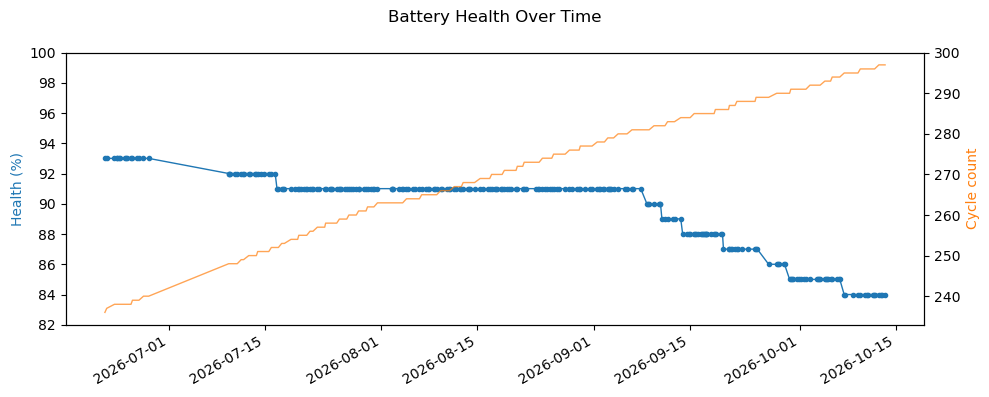

In [2]:
dates  = [r["timestamp"] for r in rows if r["health_pct"] is not None]
health = [r["health_pct"] for r in rows if r["health_pct"] is not None]
cx = [r["timestamp"] for r in rows if r["cycle_count"] is not None]
cy = [r["cycle_count"]  for r in rows if r["cycle_count"] is not None]

fig, ax1 = plt.subplots(figsize=(10, 4))
ax1.plot(dates, health, color="tab:blue", marker="o", markersize=3, linewidth=1)
ax1.set_ylabel("Health (%)", color="tab:blue")
ax1.set_ylim(min(health) - 2, 100)
if cy:
    ax2 = ax1.twinx()
    ax2.plot(cx, cy, color="tab:orange", linewidth=1, alpha=0.7)
    ax2.set_ylabel("Cycle count", color="tab:orange")
fig.suptitle("Battery Health Over Time")
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

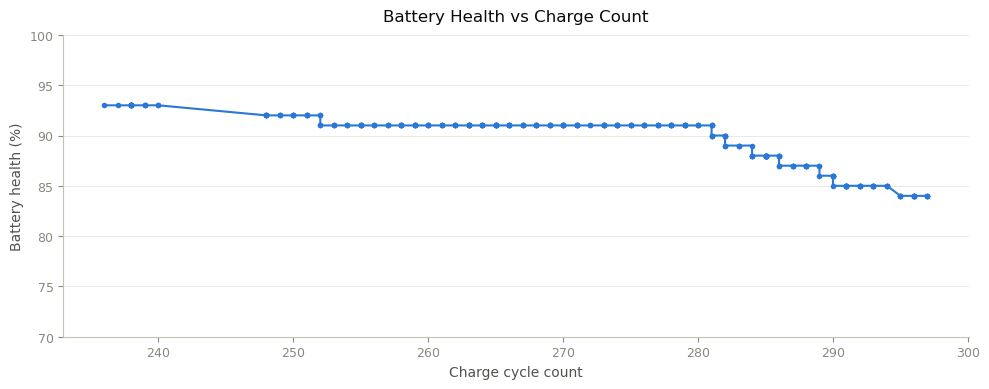

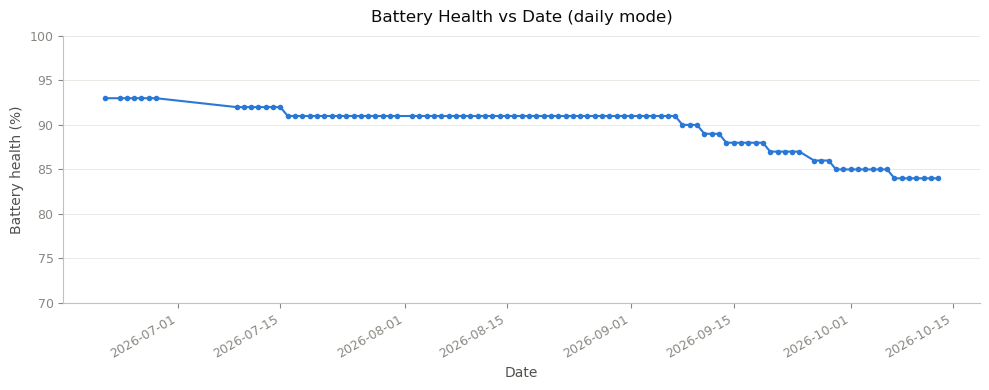

In [3]:

from statistics import mode, StatisticsError
from collections import defaultdict

# --- Plot 1: Battery Health vs Charge Count ---
hc_pairs = [(r["cycle_count"], r["health_pct"])
            for r in rows
            if r["cycle_count"] is not None and r["health_pct"] is not None]
hc_pairs.sort(key=lambda x: x[0])
cc_x = [p[0] for p in hc_pairs]
h_y  = [p[1] for p in hc_pairs]

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(cc_x, h_y, color="#2a78d6", linewidth=1.5, marker="o", markersize=4,
        markerfacecolor="#2a78d6", markeredgewidth=0)
ax.set_xlabel("Charge cycle count", color="#52514e", fontsize=10)
ax.set_ylabel("Battery health (%)", color="#52514e", fontsize=10)
ax.set_ylim(70, 100)
ax.set_title("Battery Health vs Charge Count", fontsize=12, color="#0b0b0b", pad=10)
ax.tick_params(colors="#898781", labelsize=9)
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("#c3c2b7")
ax.yaxis.grid(True, color="#e1e0d9", linewidth=0.5, zorder=0)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

# --- Plot 2: Battery Health vs Date (mode per day) ---
by_date = defaultdict(list)
for r in rows:
    if r["health_pct"] is not None:
        day = r["timestamp"].date()
        by_date[day].append(r["health_pct"])

day_mode_pairs = []
for day, vals in sorted(by_date.items()):
    try:
        m = mode(vals)
    except StatisticsError:
        m = vals[0]
    day_mode_pairs.append((day, m))

d_dates  = [p[0] for p in day_mode_pairs]
d_health = [p[1] for p in day_mode_pairs]

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(d_dates, d_health, color="#2a78d6", linewidth=1.5, marker="o", markersize=4,
        markerfacecolor="#2a78d6", markeredgewidth=0)
ax.set_xlabel("Date", color="#52514e", fontsize=10)
ax.set_ylabel("Battery health (%)", color="#52514e", fontsize=10)
ax.set_ylim(70, 100)
ax.set_title("Battery Health vs Date (daily mode)", fontsize=12, color="#0b0b0b", pad=10)
ax.tick_params(colors="#898781", labelsize=9)
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("#c3c2b7")
ax.yaxis.grid(True, color="#e1e0d9", linewidth=0.5, zorder=0)
ax.set_axisbelow(True)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()
